# G×Age and the estimate of f, by genetic correlation (overlapping SNP sets)

**Question.** Parents are measured as adults and offspring as children. The trait's genetic architecture may differ by age (G×Age), so that the adult and child expressions have a genetic correlation r_g < 1. This notebook asks:
- how the bias of f (vertical transmission) in the observed-parent, same-trait Cascade Model 2 depends on r_g;
- whether the RDR-anchored Cascade models correct it.

**Design.**
- **r_g levels:** .33, .67, .87, and 1 (no G×Age) as the reference.
- **Mating mechanisms:** primary phenotypic AM, genetic homogamy and social homogamy.
- **Populations:** 50 independent GeneEvolve populations per mechanism × r_g, 600 in all.
- **G×Age:** comes from overlapping SNP sets, adult-only, shared and child-only (Section 1). The child trait is expressed in every generation.
- **Fits:** each population is fit with Model 2 and with four RDR-anchored models.
- **Grouping of the RDR models:** the two realistic ones, which need only the child's RDR heritability, are compared in Section 4.1: RDR on the child's a, and same trait with latent parents. The two that also need the parents' RDR are in Section 4.2.

**Short answer.** Relative bias of f, (mean f̂ − .15) / .15, from 50 populations per cell:

| mechanism | model | r_g = .33 | .67 | .87 | 1 |
|---|---|---|---|---|---|
| primary AM | Model 2 | −55% | −21% | −1% | +5% |
| | RDR on the child's a | −3% | −4% | +3% | +3% |
| | same trait, latent parents | −371% | −96% | −30% | +1% |
| genetic homogamy | Model 2 | −218% | −55% | −21% | +7% |
| | RDR on the child's a | −2% | +6% | −2% | +7% |
| | same trait, latent parents | −488% | −140% | −39% | 0% |
| social homogamy | Model 2 | +5% | +2% | −3% | −1% |
| | RDR on the child's a | −1% | −2% | −4% | −2% |
| | same trait, latent parents | +731% (median −16%) | +74% (+23%) | +38% (+24%) | +7% |

- **Model 2.** Under primary AM and genetic homogamy, the bias grows steeply as r_g falls. Under social homogamy there is none.
- **RDR on the child's a removes the bias** at every r_g and under every mechanism, within ±7%.
- **Same trait with latent parents** works without G×Age, but with G×Age it is worse than Model 2. Under social homogamy it is unstable.
- **Section 4.2:**
  - RDR on both a: partial correction, with a new bias under social homogamy.
  - Different traits with latent parents: small biases, but bimodal under social homogamy, and it needs the true µ.

**Files.** Everything is in `output_snpsets/`; plots in `output_snpsets/plots/`. To rerun:
- `06_simulate_overlap.py`, once per r_g level; the commands are in its docstring;
- then `Rscript 03_fit_sim.R --out output_snpsets`;
- then `Rscript 05_fit_rdr.R --out output_snpsets`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

OUT = Path("output_snpsets")
PLOTS = OUT / "plots"; PLOTS.mkdir(parents=True, exist_ok=True)
truth = pd.read_csv(Path("output") / "truth" / "gxage_truth.csv")   # generating values (02_population_fits.R)
diag  = pd.read_csv(OUT / "sim" / "diagnostics.csv")       # SNP sets and realized r_g (06_simulate_overlap.py)
info  = pd.read_csv(OUT / "sim" / "rep_info.csv")
sim   = pd.read_csv(OUT / "sim_fits.csv")                  # Model 2 (03_fit_sim.R --out output_snpsets)
rdr   = pd.read_csv(OUT / "rdr_fits.csv")                  # the RDR-anchored models (05_fit_rdr.R --out output_snpsets)
for d in (diag, info, sim, rdr):
    d["rg"] = (1 - d.u).round(2)                           # design r_g = shared / adult SNPs (1 - u)

F_TRUE = .15
RG = sorted(sim.rg.unique())
MECHS = ["primary", "genetic", "social"]
MLAB  = {"primary": "primary phenotypic AM", "genetic": "genetic homogamy", "social": "social homogamy"}
MODEL_LAB = {"M2": "Model 2 (no RDR)", "EstA": "RDR on the child's a", "SameLat": "same trait, latent parents",
             "FixA": "RDR on both a", "DiffLat": "different traits, latent parents"}
REAL  = ["M2", "EstA", "SameLat"]                          # corrections that need only the child's RDR
OTHER = ["M2", "FixA", "DiffLat"]
# reference palette slots 1-3, with the mechanism-to-colour mapping of AMTypeCheck; models as in 04_results
COLOR = {"genetic": "#2a78d6", "social": "#eb6834", "primary": "#1baf7a"}
INK, INK2, RULE = "#0b0b0b", "#52514e", "#dcdad5"
MCOL = {"M2": INK2, "EstA": "#4a3aa7", "FixA": "#e87ba4", "SameLat": "#008300", "DiffLat": "#eda100"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": RULE,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": RULE,
                     "grid.linewidth": .6, "font.size": 10, "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.dpi": 150})
pd.set_option("display.width", 160, "display.max_columns", 30)

def rgtick(ax):
    ax.set_xticks(RG); ax.set_xticklabels([f"{r:g}" for r in RG])
    ax.set_xlabel("r_g between parental and offspring traits")
    ax.set_xlim(min(RG) - .06, 1.06)

F = pd.concat([sim[sim.parameter == "f11"].assign(model="M2"), rdr[rdr.parameter == "f11"]], ignore_index=True)
F = F[["model", "mechanism", "rep", "pooled", "rg", "estimate"]]
g = F[~F.pooled].groupby(["mechanism", "model", "rg"]).estimate
S = pd.DataFrame({"populations": g.size(), "mean f̂": g.mean(), "median f̂": g.median(), "MC SE": g.std() / np.sqrt(g.size())})
S["bias"] = S["mean f̂"] - F_TRUE
S["relative bias (%)"] = 100 * S.bias / F_TRUE
S["z"] = S.bias / S["MC SE"]

def byRG(col, models, digits=1):
    # one row per mechanism x model, one column per r_g
    t = S[col].unstack("rg").reindex(MECHS, level=0).reindex(models, level=1)
    t.columns = [f"r_g = {r:g}" for r in t.columns]
    return t.rename(index=MODEL_LAB, level=1).round(digits)

## 1. What is simulated

**G×Age through overlapping SNP sets.** Each population has 1,000 causal SNPs in three sets:
- **adult-only:** an adult effect only;
- **shared:** the same effect at both ages;
- **child-only:** a child effect only.

The child-only effects are scaled so that both ages have the same founder genetic variance, VG0 = δ² + a². The genetic correlation between adult and child expression is the shared SNPs' share of that variance:

$$r_g = \frac{\mathrm{var}(G_\text{shared})}{VG_0} \approx \frac{\text{shared SNPs}}{\text{adult SNPs}}.$$

The adult-only and child-only sets have the same size, so the unique share u = 1 − r_g is the same at both ages. Four levels:

| r_g | adult-only | shared | child-only | adult SNPs (PGS) |
|---|---|---|---|---|
| .33 | 400 | 200 | 400 | 600 (240) |
| .67 | 250 | 500 | 250 | 750 (300) |
| .87 | 115 | 770 | 115 | 885 (354) |
| 1 (no G×Age) | 0 | 1,000 | 0 | 1,000 (400) |

The realized r_g varies between populations with the SNPs and effects drawn (table below).

**The child trait is expressed in every generation**, as GeneEvolve's second trait:

$$Y_\text{child} = G_\text{shared} + G_\text{child-only} + F + E_\text{child}.$$

The trios pair the parents' adult phenotypes with the offspring's child phenotype.

**What G×Age does not touch.**
- The PGS carries the adult effects, as when it comes from an adult GWAS. Child-only SNPs are not in it.
- Spouses assort on their adult mating phenotype.
- Vertical transmission comes from the parents' adult phenotypes: F = f·(Yp + Ym).
- No generation's child phenotype feeds back into mating or transmission.

### Simulation settings (GeneEvolve, `06_simulate_overlap.py`)

| Setting | Value |
|---|---|
| Mating mechanisms | primary phenotypic AM, genetic homogamy, social homogamy |
| Populations | 50 per mechanism and r_g level, 600 in all. Every level has its own populations: seed = 20260928 + 1000 × (0 primary, 1 genetic, 2 social) + population number + an offset of 210,000 (r_g = .33), 200,000 (.67), 220,000 (.87) or 230,000 (1) |
| Population size | 10,000 individuals per generation |
| Founders (generation 0) | genotypes in Hardy–Weinberg and linkage equilibrium, F = 0, E ~ N(0, VE) |
| Generations | 30 matings with AM and VT. The child trait is computed in every generation; the offspring of the 30th mating form the trios |
| Causal variants | 1,000 at every level, in the three sets above. Allele frequencies ~ Uniform(.05, .50) |
| PGS / latent loci | 40% of the adult SNPs form the PGS and the rest the latent score (40% = δ² / (δ² + a²) at BASE) |
| Adult effects β | N(0, 1), rescaled so the founders' PGS and latent-score variances are exactly δ² and a² |
| Shared set | a random subset of the adult SNPs; the child effect equals the adult effect |
| Child-only effects β_C | N(0, 1), rescaled so the child's founder genetic variance is exactly VG0 |
| Child residual | E_child ~ N(0, VE), independent of the adult residual |
| Assortment | on the adult latent mating phenotype γ̃ = AM_G·(AO + AL) + AM_E·(F + E). The target spousal correlation of γ̃ is .4 at every mating |
| Vertical transmission | F = f·(Yp + Ym) with f = .15, from the parents' adult phenotypes; the child trait has the same F |
| Trios | one random offspring per family: 3,973–4,129 per population (mean 4,053), about 202,000 per mechanism × r_g pooled |
| Data columns | Yp1, Ym1 (adult) and Yo1 (child), each centred, and the haplotypic PGS Tp1, NTp1, Tm1, NTm1 divided by δ |

**Realized SNP sets and r_g.**
- **Founders:** r_g is var(G_shared) / VG0.
- **Final generation:** r_g is the correlation of the offspring's adult and child genetic values.
- **Why the final-generation r_g is higher under AM.** AM raises the variance of the adult genetic value. The shared part carries that increase into the child, scaled by (1 − u)², while the child-only part does not take part in it.

In [2]:
d = diag.merge(info[["mechanism", "rep", "u", "n_trios"]], on=["mechanism", "rep", "u"])
g = d.groupby(["rg", "mechanism"])
pd.DataFrame({"populations": g.size(),
              "adult-only / shared / child-only SNPs": g.n_adult_only.first().astype(str) + " / " + g.n_shared.first().astype(str)
                                                       + " / " + g.n_child_only.first().astype(str),
              "PGS SNPs": g.n_pgs.first(),
              "r_g founders: mean": g.rg_base.mean(), "min": g.rg_base.min(), "max": g.rg_base.max(),
              "r_g final generation: mean": g.rg_final_generation.mean(),
              "trios: mean": g.n_trios.mean()}).reindex(MECHS, level=1).round(3)

populations adult-only / shared / child-only SNPs  PGS SNPs  r_g founders: mean    min    max  r_g final generation: mean  trios: mean
rg   mechanism                                                                                                                                        
0.33 primary             50                       400 / 200 / 400       240               0.332  0.280  0.412                       0.379      4047.00
     genetic             50                       400 / 200 / 400       240               0.332  0.280  0.407                       0.412      4054.08
     social              50                       400 / 200 / 400       240               0.333  0.271  0.394                       0.332      4051.08
0.67 primary             50                       250 / 500 / 250       300               0.664  0.574  0.721                       0.719      4052.14
     genetic             50                       250 / 500 / 250       300               0.667  0.608  0.728                       0.752      4042.54
     social              50                       250 / 500 / 250       300               0.662  0.600  0.709                       0.664      4054.40
0.87 primary             50                       115 / 770 / 115       354               0.867  0.819  0.900                       0.896      4052.32
     genetic             50                       115 / 770 / 115       354               0.872  0.824  0.902                       0.917      4056.50
     social              50                       115 / 770 / 115       354               0.873  0.826  0.906                       0.874      4058.14
1.00 primary             50                          0 / 1000 / 0       400               1.000  1.000  1.000                       1.000      4046.74
     genetic             50                          0 / 1000 / 0       400               1.000  1.000  1.000                       1.000      4063.88
     social              50                          0 / 1000 / 0       400               1.000  1.000  1.000                       1.000      4057.16

### Generating values

These are the equilibrium values of the Cascade Validation. The base values are δ² = .2, a² = .3, VE = .5 and k = j = .5, so VG0 = .5 and h² = .5 in the founders. Spouses correlate .4 on γ̃ (am), and f = .15.

Within each mechanism, δ, a and VE are multiplied by one common factor so that the parents' equilibrium VY is exactly 1. f and am are not rescaled.

Columns:
- **AM_G, AM_E:** the mechanism's multipliers on the genetic and on the F + E paths into γ̃.
- **µ:** the copath between spouses' γ̃.
- **gc = gt:** the AM-induced covariance between two PGS haplotypes, within and across parents.
- **ic:** the same covariance between a PGS haplotype and a latent haplotype.
- **r(Yp, Ym):** the spousal phenotypic correlation.

In [3]:
MECH_SPEC = {"primary": dict(am=.4, AM_G=1, AM_E=1), "genetic": dict(am=.4, AM_G=1, AM_E=0),
             "social":  dict(am=.4, AM_G=0, AM_E=1)}
g = (truth[(truth.u == 0) & (truth.f == F_TRUE) & truth.mating.isin(MECHS)]
     .pivot_table(index="mating", columns="quantity", values="value").reindex(MECHS))
for k in ("am", "AM_G", "AM_E"):
    g[k] = [MECH_SPEC[m][k] for m in g.index]
cols = {"delta": "δ", "a": "a", "VE": "VE", "VG0": "VG0 = δ² + a²", "f": "f", "am": "am", "AM_G": "AM_G",
        "AM_E": "AM_E", "mu": "µ", "VF": "VF", "gc": "gc = gt", "ic": "ic", "Yp_Ym": "r(Yp, Ym)"}
g[list(cols)].rename(columns=cols).rename_axis(index="mechanism", columns=None).round(3)

,δ,a,VE,VG0 = δ² + a²,f,am,AM_G,AM_E,µ,VF,gc = gt,ic,"r(Yp, Ym)"
mechanism,,,,,,,,,,,,,
primary,0.349,0.427,0.304,0.304,0.15,0.4,1,1,0.400,0.063,0.036,0.044,0.400
genetic,0.326,0.399,0.265,0.265,0.15,0.4,1,0,0.905,0.058,0.067,0.082,0.283
social,0.396,0.485,0.393,0.393,0.15,0.4,0,1,0.891,0.056,0.001,0.002,0.246


## 2. How the bias of f in Model 2 depends on r_g

### Model 2 fits

Model 2 is fit to every population, and once to the 50 populations of each mechanism × r_g pooled (about 202,000 trios). Each fit uses `testF` from `SensitivityAnalyses/FTestValidity/conditions.R` (`03_fit_sim.R --out output_snpsets`):
- **Mating multipliers.** AM_E is fixed at 1 and AM_G estimated (primary AM, social homogamy), or AM_G is fixed at 1 and AM_E estimated (genetic homogamy).
- **Search.** The free fit starts from the parents' true values, and again from f = −.2, 0, .1, .2 and .4 (`mxTryHard`, 5 extra tries per start). The best fit is kept.
- **Truth.** The truth for every parameter is the parents' (adult) value; f's truth is .15.

### Bias of f by r_g

The table gives, for each mechanism and r_g, the mean of the 50 population estimates of f, its Monte Carlo SE (SD / √50), the bias (mean − .15) and z = bias / MC SE. The pooled fit of the 50 populations is next to it. Every free fit ended with OpenMx status 0 or 1.

**Relative bias of f, Model 2** (mean of 50 populations; true f = .15):

| r_g | primary AM | genetic homogamy | social homogamy |
|---|---|---|---|
| .33 | −55% (f̂ = .067) | −218% (f̂ = −.178) | +5% |
| .67 | −21% | −55% | +2% |
| .87 | −1% | −21% | −3% |
| 1 (no G×Age) | +5% | +7% | −1% |

- **No G×Age (r_g = 1).** Model 2 is close to unbiased. The primary and genetic means are 5–7% above .15, with z = 2.0 and 1.7. This small offset is the simulation's baseline, not G×Age: the populations have finite loci and are not exactly at the asymptotic equilibrium.
- **Primary AM and genetic homogamy.** The bias is negative, and it grows quickly as r_g falls.
  - Genetic homogamy is the most sensitive: f̂ is already 21% too low at r_g = .87, and has the wrong sign at r_g = .33.
  - Under primary AM, r_g = .87 is harmless (−1%), but f̂ is 21% too low at .67 and 55% too low at .33.
- **Social homogamy.** G×Age does not bias Model 2: the relative bias stays within ±5% at every r_g (|z| < 1.6).
- **Pooled fits.** They agree with the means of the 50 populations to within .011 everywhere.

**Why the mechanisms differ.** G×Age changes only the child's genetic value. The PGS predicts only its shared part, so the child's PGS effect is about r_g·δ, while the parents' is δ. Model 2 has a single δ for both generations.
- Under genetic AM, the transmitted and non-transmitted haplotypes covary (gc, gt). So part of cov(Yo, NT) runs through the child's own PGS effect, and Model 2 credits it with the wrong δ. f is what absorbs the misfit, and the AM-induced covariance is largest under genetic homogamy (gc = .067, against .036 under primary AM).
- Under social homogamy, spouses are almost uncorrelated genetically (gc = .001). The non-transmitted PGS reaches the child only through F, which comes from the parents' adult phenotypes, so the child's genetic value does not enter the estimate of f.

In [4]:
sf = sim[sim.parameter == "f11"]
t = S.xs("M2", level="model").drop(columns="median f̂").reindex(MECHS, level=0)
t["pooled f̂"] = sf[sf.pooled].set_index(["mechanism", "rg"]).estimate
t["pooled SE"] = sf[sf.pooled].set_index(["mechanism", "rg"]).f_SE
print("status codes of the free fits:", sf.status_free.value_counts().to_dict())
t.round(4).round({"relative bias (%)": 1, "z": 2})

status codes of the free fits: {1: 314, 0: 298}


populations  mean f̂   MC SE    bias  relative bias (%)      z  pooled f̂  pooled SE
mechanism rg                                                                                        
primary   0.33           50   0.0669  0.0136 -0.0831              -55.4  -6.11     0.0639     0.0113
          0.67           50   0.1187  0.0056 -0.0313              -20.9  -5.55     0.1194     0.0062
          0.87           50   0.1486  0.0045 -0.0014               -1.0  -0.32     0.1490     0.0049
          1.00           50   0.1582  0.0041  0.0082                5.4   1.98     0.1578     0.0042
genetic   0.33           50  -0.1776  0.0147 -0.3276             -218.4 -22.24    -0.1886     0.0137
          0.67           50   0.0673  0.0134 -0.0827              -55.1  -6.18     0.0739     0.0118
          0.87           50   0.1184  0.0068 -0.0316              -21.1  -4.64     0.1208     0.0075
          1.00           50   0.1600  0.0060  0.0100                6.7   1.67     0.1609     0.0059
social    0.33           50   0.1569  0.0045  0.0069                4.6   1.55     0.1576     0.0045
          0.67           50   0.1533  0.0046  0.0033                2.2   0.71     0.1536     0.0040
          0.87           50   0.1460  0.0041 -0.0040               -2.7  -0.99     0.1463     0.0038
          1.00           50   0.1491  0.0045 -0.0009               -0.6  -0.20     0.1497     0.0036

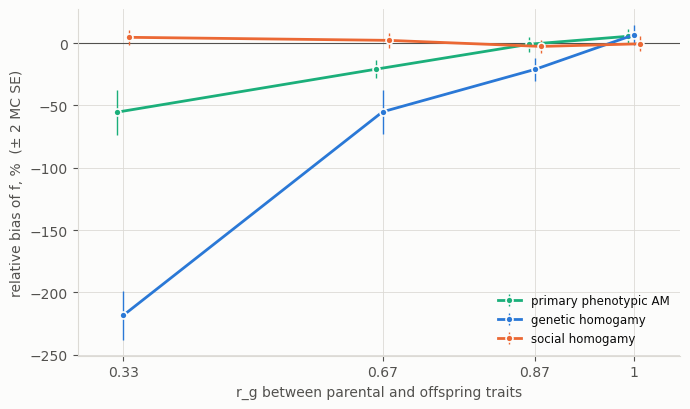

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.axhline(0, color=INK2, lw=.8)
for k, mech in enumerate(MECHS):
    tt = t.loc[mech].reset_index()
    ax.errorbar(tt.rg + (k - 1) * .008, tt["relative bias (%)"], yerr=200 * tt["MC SE"] / F_TRUE, color=COLOR[mech],
                lw=2, marker="o", ms=5, mec="#fcfcfb", mew=1.2, elinewidth=1, capsize=0, label=MLAB[mech])
ax.set_ylabel("relative bias of f, %  (± 2 MC SE)")
rgtick(ax)
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout(); fig.savefig(PLOTS / "bias_f.png"); plt.show()

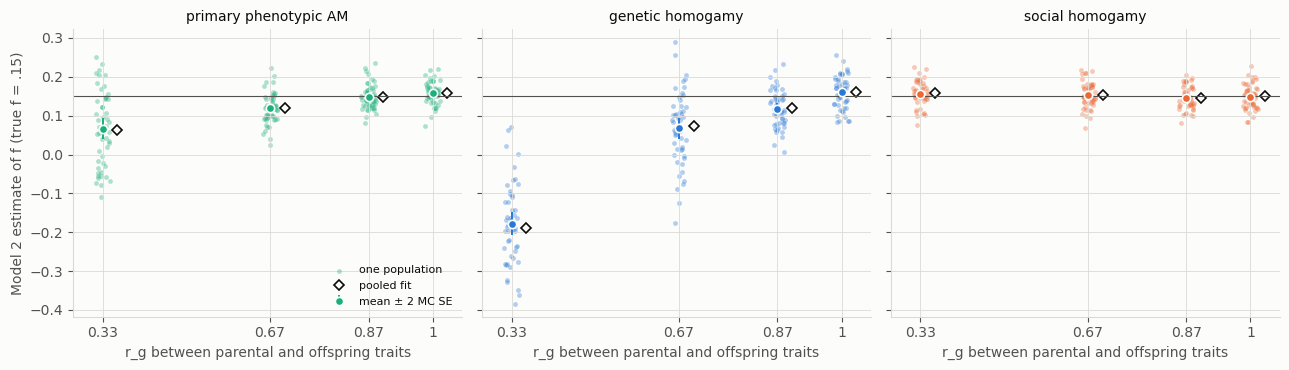

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
reps = sf[~sf.pooled]
for ax, mech in zip(axes, MECHS):
    x = reps[reps.mechanism == mech]
    ax.scatter(x.rg + np.random.default_rng(1).uniform(-.015, .015, len(x)), x.estimate, s=12, color=COLOR[mech],
               alpha=.35, lw=0, label="one population")
    tt = t.loc[mech].reset_index()
    ax.errorbar(tt.rg, tt["mean f̂"], yerr=2 * tt["MC SE"], fmt="o", ms=6, color=COLOR[mech], mec="#fcfcfb", mew=1.2,
                elinewidth=1.4, capsize=0, label="mean ± 2 MC SE")
    ax.plot(tt.rg + .03, tt["pooled f̂"], "D", ms=5, color=INK, mfc="#fcfcfb", mew=1.2, ls="none", label="pooled fit")
    ax.axhline(F_TRUE, color=INK2, lw=.8)
    ax.set_title(MLAB[mech], fontsize=10, color=INK)
    rgtick(ax)
axes[0].set_ylabel("Model 2 estimate of f (true f = .15)")
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(PLOTS / "sim_f_estimates.png"); plt.show()

## 3. Where G×Age goes in Model 2

Mean estimates of the other parameters over the 50 populations, against the parents' true values. The truth column is the same at every r_g: G×Age changes only the child.

- **δ follows the child.** δ̂ is close to the parents' δ at r_g = 1, and falls with r_g. It is 88–91% of the parents' δ at r_g = .87, 68–74% at .67, and 37–43% at .33, the same under all three mechanisms. This is the single δ fitting the child's PGS effect (about r_g·δ) rather than the parents'.
- **The child-only genetic variance becomes residual.** Under primary AM and social homogamy, VÊ rises from its true value (.304, .393) to .537 and .711 at r_g = .33. Under genetic homogamy, VÊ moves less.
- **The mating multipliers absorb the misfit.**
  - Primary AM: AM_G (true 1) is .97 at r_g = 1, 1.23 at .87, 1.78 at .67 and 3.91 at .33.
  - Genetic homogamy: AM_E (true 0) is .03 at r_g = 1 and −.54 at .33. It is negative in 21 of 50 fits at r_g = 1 and 48 of 50 at .33, so a negative AM_E alone does not signal G×Age.
  - Social homogamy: AM_G (true 0) rises from .01 at r_g = 1 to .31 at .33. µ falls from .91 to .34 (true .89), yet f̂ is unaffected (Section 2).

In [7]:
PARS = ["delta11", "a11", "VE11", "f11", "mu11", "AMGenMulti", "AMEnvMulti", "VF11", "VY11"]
x = sim[~sim.pooled & sim.parameter.isin(PARS)]
est = x.pivot_table(index=["mechanism", "parameter"], columns="rg", values="estimate", aggfunc="mean")
est.columns = [f"r_g = {r:g}" for r in est.columns]
est.insert(0, "true (parents)", x.groupby(["mechanism", "parameter"]).true.first())
est.reindex(MECHS, level=0).reindex(PARS, level=1).dropna(how="all").round(3)

true (parents)  r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism parameter                                                              
primary   delta11              0.349       0.142       0.251       0.310    0.346
          a11                  0.427       0.320       0.391       0.397    0.415
          VE11                 0.304       0.537       0.420       0.358    0.307
          f11                  0.150       0.067       0.119       0.149    0.158
          mu11                 0.400       0.161       0.258       0.350    0.420
          AMGenMulti           1.000       3.907       1.784       1.228    0.974
          VF11                 0.063       0.034       0.041       0.063    0.072
          VY11                 1.000       0.907       0.947       0.970    0.990
genetic   delta11              0.326       0.141       0.241       0.297    0.324
          a11                  0.399       0.477       0.397       0.404    0.382
          VE11                 0.265       0.301       0.341       0.290    0.275
          f11                  0.150      -0.178       0.067       0.118    0.160
          mu11                 0.905       0.741       1.122       0.978    0.913
          AMEnvMulti           0.000      -0.535      -0.090      -0.040    0.031
          VF11                 0.058       0.095       0.032       0.041    0.069
          VY11                 1.000       0.891       0.933       0.973    0.986
social    delta11              0.396       0.146       0.271       0.350    0.398
          a11                  0.485       0.262       0.394       0.469    0.482
          VE11                 0.393       0.711       0.548       0.440    0.395
          f11                  0.150       0.157       0.153       0.146    0.149
          mu11                 0.891       0.338       0.514       0.800    0.909
          AMGenMulti           0.000       0.310       0.105       0.016    0.011
          VF11                 0.056       0.061       0.060       0.055    0.058
          VY11                 1.000       0.960       0.978       0.992    1.001

## 4. Do RDR-anchored models correct the bias?

Four Cascade models use RDR heritability to pin a latent genetic effect. They are fit to the same 600 datasets as Model 2 (`05_fit_rdr.R --out output_snpsets`), with the same search.

**The two realistic corrections** need only the child's RDR heritability, i.e. RDR in the generation whose phenotype is measured:
- **RDR on the child's a** (`UniSEMPGS_Cascade_DiffTrait_ObservedYPYM_EstimatedAParent.R`):
  - observed parental phenotypes;
  - its own δ and a for parents and offspring;
  - RDR fixes the offspring's a_o; the parents' a_p is estimated;
  - the mating multipliers of Model 2.
- **Same trait, latent parents** (`UniSEMPGS_Cascade_SameTrait_LatentYPYM.R`):
  - only the child's phenotype and the four PGS haplotypes;
  - one δ and one a for both generations;
  - the child's RDR fixes a;
  - both mating multipliers fixed at the true mechanism, which is not identified with latent parents.

**The other two** also need the parents' RDR heritability (Section 4.2).

**RDR inputs.** These are the true population values, so they carry no RDR sampling error.
- **Parents:** the adult trait's RDR heritability.
- **Child:** what RDR run on children would estimate, i.e. all of the child's genetic variance, including the child-only part.
- **Why the child input is "too large" for the models.** They treat the child-only part as residual, since it is unrelated to the PGS and to the parents' latent score. So the child input exceeds the value that would make them correctly specified. At r_g = 1 the two values coincide.

In [8]:
h2 = rdr[rdr.parameter == "f11"].groupby(["mechanism", "rg"])[["h2_RDR_parent", "h2_RDR_child"]].max()
h2 = h2.unstack("rg").reindex(MECHS)
h2.columns = [f"{c[0].replace('h2_RDR_', '')}, r_g = {c[1]:g}" for c in h2.columns]
print("RDR inputs: the parents' value is used by 'RDR on both a' and the different-trait latent model only")
h2.round(3)

RDR inputs: the parents' value is used by 'RDR on both a' and the different-trait latent model only


,"parent, r_g = 0.33","parent, r_g = 0.67","parent, r_g = 0.87","parent, r_g = 1","child, r_g = 0.33","child, r_g = 0.67","child, r_g = 0.87","child, r_g = 1"
mechanism,,,,,,,,
primary,0.185,0.185,0.185,0.185,0.245,0.213,0.195,0.185
genetic,0.141,0.141,0.141,0.141,0.205,0.171,0.152,0.141
social,0.309,0.309,0.309,0.309,0.346,0.326,0.315,0.309


### 4.1 The realistic corrections: RDR on the child's a, and same trait with latent parents

The tables below show, for Model 2 and the two realistic corrections:
- the relative bias of the mean f̂ and of the median f̂;
- the MC SE of the mean;
- the OpenMx status codes of the fits.

The figure shows the relative bias of the mean ± 2 MC SE, with Model 2 as the dashed reference. A point beyond a panel's y range is drawn at the edge as a triangle labelled with its value.

In [9]:
print("relative bias of f (%): mean of the 50 population estimates minus .15, divided by .15")
display(byRG("relative bias (%)", REAL))
print("relative bias of f (%), median of the 50 population estimates")
display(byRG("median f̂", REAL, 4).sub(F_TRUE).div(F_TRUE).mul(100).round(1))
print("MC SE of a mean f̂")
display(byRG("MC SE", REAL, 4))
print("status codes:", rdr[(rdr.parameter == "f11") & rdr.model.isin(REAL)].groupby("model").status.value_counts()
      .unstack(fill_value=0).to_dict("index"))

relative bias of f (%): mean of the 50 population estimates minus .15, divided by .15


r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                  
primary   Model 2 (no RDR)                 -55.4       -20.9        -1.0      5.4
          RDR on the child's a              -3.4        -3.6         2.9      3.4
          same trait, latent parents      -370.9       -95.6       -29.7      1.1
genetic   Model 2 (no RDR)                -218.4       -55.1       -21.1      6.7
          RDR on the child's a              -2.1         5.6        -1.7      6.6
          same trait, latent parents      -488.4      -140.5       -39.0      0.2
social    Model 2 (no RDR)                   4.6         2.2        -2.7     -0.6
          RDR on the child's a              -1.3        -1.7        -4.0     -1.7
          same trait, latent parents       730.8        73.8        37.8      7.1

relative bias of f (%), median of the 50 population estimates


r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                  
primary   Model 2 (no RDR)                 -55.9       -21.3        -5.7      4.9
          RDR on the child's a              -1.6        -5.0        -0.8      5.3
          same trait, latent parents      -408.7       -95.7       -31.1      2.1
genetic   Model 2 (no RDR)                -222.3       -49.7       -22.7     11.6
          RDR on the child's a               0.9         9.7        -1.7      9.1
          same trait, latent parents      -498.7      -140.1       -35.0      3.2
social    Model 2 (no RDR)                   3.9         0.6        -3.8      1.3
          RDR on the child's a              -2.4        -3.7        -6.0     -0.1
          same trait, latent parents       -15.6        22.7        24.0      4.7

MC SE of a mean f̂


r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                  
primary   Model 2 (no RDR)                0.0136      0.0056      0.0045   0.0041
          RDR on the child's a            0.0052      0.0042      0.0040   0.0038
          same trait, latent parents      0.0188      0.0052      0.0031   0.0017
genetic   Model 2 (no RDR)                0.0147      0.0134      0.0068   0.0060
          RDR on the child's a            0.0058      0.0058      0.0052   0.0061
          same trait, latent parents      0.0082      0.0074      0.0039   0.0030
social    Model 2 (no RDR)                0.0045      0.0046      0.0041   0.0045
          RDR on the child's a            0.0040      0.0041      0.0038   0.0043
          same trait, latent parents      0.2387      0.0456      0.0218   0.0075

status codes: {'EstA': {0: 249, 1: 362, 6: 1}, 'SameLat': {0: 48, 1: 564, 6: 0}}


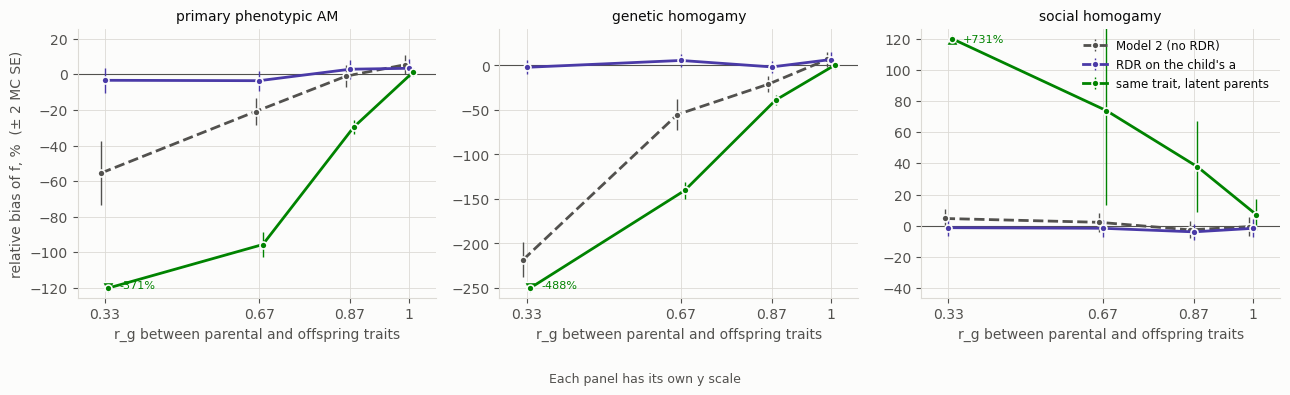

In [10]:
def modelLines(models, fname, ylim=None, leg=(0, "lower right")):
    # relative bias of the mean f̂ (± 2 MC SE) by r_g; ylim = {mechanism: (lo, hi)} clips a panel, and a point beyond
    # it is drawn at the edge as a triangle labelled with its value; leg = (panel, location) of the legend
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
    for ax, mech in zip(axes, MECHS):
        ax.axhline(0, color=INK2, lw=.8)
        lo, hi = (ylim or {}).get(mech, (-np.inf, np.inf))
        for k, mod in enumerate(models):
            c = S.loc[(mech, mod)].reset_index()
            x, y, e = c.rg + (k - 1) * .008, c["relative bias (%)"], 200 * c["MC SE"] / F_TRUE
            ax.errorbar(x, y.clip(lo, hi), yerr=np.where((y > hi) | (y < lo), 0, e), color=MCOL[mod], lw=2,
                        ls="--" if mod == "M2" else "-", marker="o", ms=5, mec="#fcfcfb", mew=1.2, elinewidth=1,
                        capsize=0, label=MODEL_LAB[mod])
            for xi, yi in zip(x[(y > hi) | (y < lo)], y[(y > hi) | (y < lo)]):
                ax.plot(xi, min(max(yi, lo), hi), "^" if yi > hi else "v", ms=9, color=MCOL[mod], mec="#fcfcfb")
                ax.annotate(f"{yi:+.0f}%", (xi, min(max(yi, lo), hi)), xytext=(8, -3 if yi > hi else 0),
                            textcoords="offset points", fontsize=8, color=MCOL[mod])
        if mech in (ylim or {}):
            ax.set_ylim(lo - .04 * (hi - lo), hi + .04 * (hi - lo))
        ax.set_title(MLAB[mech], fontsize=10, color=INK)
        rgtick(ax)
    axes[0].set_ylabel("relative bias of f, %  (± 2 MC SE)")
    axes[leg[0]].legend(*axes[0].get_legend_handles_labels(), loc=leg[1], fontsize=8.5)
    fig.suptitle("Each panel has its own y scale", y=-.04, fontsize=9, color=INK2)
    fig.tight_layout(); fig.savefig(PLOTS / fname); plt.show()

modelLines(REAL, "rdr_realistic_bias_f.png", ylim={"primary": (-120, 20), "genetic": (-250, 30), "social": (-40, 120)},
           leg=(2, "upper right"))

**RDR on the child's a corrects the bias at every r_g, under every mechanism.**
- **Bias.** The relative bias of the mean is within ±7% in all 12 conditions, with |z| < 1.7. It does not trend with r_g. At r_g = .33 it is −3%, −2% and −1% (primary, genetic, social); Model 2 has −55%, −218% and +5%.
- **Baseline.** At r_g = 1 it sits 3% and 7% above .15 under primary AM and genetic homogamy, the same offset as Model 2 (Section 2).
- **Precision.** At r_g = 1, the SD of f̂ across populations is .027, .043 and .031, against Model 2's .029, .042 and .032. With G×Age it is more precise than Model 2 under primary AM and genetic homogamy: the MC SE at r_g = .33 is .0052 and .0058, against .0136 and .0147.
- **Convergence.** Every fit ended with status 0 or 1, except one with status 6 (primary AM, r_g = .33, f̂ = .209).

**Why it works** (median estimates in the table below; every parameter in the figure after it). The model gives the child its own δ_o and estimates the parents' a_p.
- **δ̂_o follows the child's PGS effect, r_g·δ.** Under primary AM it is .122, .227 and .300 at r_g = .33, .67 and .87, where r_g·δ = .115, .234 and .303.
- **The parents' side absorbs the rest.** The child's RDR pins â_o, so the shrinking latent parent–child covariance is matched on the parents' side. Under primary AM, â_p is .130, .292 and .366 at r_g = .33, .67 and .87 (true .427). The parents' variance that â_p no longer carries moves to VÊ_p: .589 at r_g = .33, against .304.
- **So f is right, but the parents' a and VE are not.** Under G×Age, this model's â_p and VÊ_p are not the parents' latent genetic and residual variance.

In [11]:
P_EST = {"a_p11": "a_p", "a_o11": "a_o", "delta_p11": "δ_p", "delta_o11": "δ_o", "VE_parent": "VE_p", "VE_offspring": "VE_o"}
P_LAT = {"delta11": "δ", "a11": "a", "VE11": "VE", "mu11": "µ", "VF11": "VF"}

def parTable(model, labels):
    x = rdr[~rdr.pooled & (rdr.model == model) & rdr.parameter.isin(labels)].assign(par=lambda d: d.parameter.map(labels))
    # medians: a few degenerate same-trait latent fits would dominate a mean
    est = x.pivot_table(index=["mechanism", "par"], columns="rg", values="estimate", aggfunc="median")
    est.columns = [f"r_g = {r:g}" for r in est.columns]
    est.insert(0, "true at r_g = 1", x[x.rg == 1].groupby(["mechanism", "par"]).true.first())
    return est.reindex(MECHS, level=0).reindex(list(dict.fromkeys(labels.values())), level=1).round(3)

print(MODEL_LAB["EstA"], "- median estimates"); display(parTable("EstA", P_EST))

RDR on the child's a - median estimates


true at r_g = 1  r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism par                                                               
primary   a_p             0.427       0.130       0.292       0.366    0.405
          a_o             0.427       0.536       0.496       0.456    0.428
          δ_p             0.349       0.407       0.388       0.362    0.344
          δ_o             0.349       0.122       0.227       0.300    0.346
          VE_p            0.304       0.589       0.500       0.406    0.324
          VE_o            0.304       0.308       0.307       0.304    0.297
genetic   a_p             0.399       0.126       0.244       0.366    0.377
          a_o             0.399       0.501       0.462       0.426    0.394
          δ_p             0.326       0.415       0.383       0.350    0.329
          δ_o             0.326       0.114       0.217       0.287    0.325
          VE_p            0.265       0.546       0.470       0.332    0.291
          VE_o            0.265       0.263       0.264       0.267    0.268
social    a_p             0.485       0.121       0.288       0.436    0.488
          a_o             0.485       0.610       0.567       0.519    0.478
          δ_p             0.396       0.396       0.400       0.399    0.399
          δ_o             0.396       0.136       0.263       0.349    0.397
          VE_p            0.393       0.693       0.604       0.477    0.391
          VE_o            0.393       0.398       0.396       0.398    0.403

#### Every parameter of RDR on the child's a

The figure has one panel per free parameter of the model (the means aside), plus one derived quantity, a_o·Γ_p.
- **Points and bars.** Each point is the median of the 50 population estimates, and the bar is the interquartile range across populations.
- **Why medians.** A few fits have extreme values that would dominate a mean: µ̂ up to 575 under social homogamy, AM_E down to −7.4 under genetic homogamy, and AM_G up to 10.1 under primary AM.
- **Dashed lines: the truth**, in each mechanism's colour.
  - **The parents' parameters:** the parents' values, the same at every r_g.
  - **The child's parameters:** the values that make the model correctly specified when the child-only genetic variance is treated as residual: δ_o = r_g·δ, a_o = r_g·a, VE_o = VE + (1 − r_g²)·VG0, and VY_o is the child's phenotypic variance.

**Recovered at every r_g.** These are the quantities the PGS and the observed phenotypes pin down:
- f, δ_o, VY_p, VY_o, VF, gc, Ω_p and w have medians within .025 of the truth at every r_g.
- δ̂_o follows r_g·δ.
- a_o·Γ_p, the latent genetic term of cov(Yo, Yp), is within .016 of its truth at every r_g.

**a_o and VE_o are off their dashed lines by design.** The child's RDR input counts the child-only genetic variance as genetic.
- So â_o lies above its line: .536 against .141 at r_g = .33 under primary AM.
- VÊ_o lies below its line, flat at the child's environmental variance VE: .297–.308 under primary AM, where VE = .304.

**The parents' latent side absorbs G×Age.** With a_o pinned high, only the product a_o·Γ_p is identified, so Γ_p and everything tied to the parents' latent score shrink with r_g.
- **Shrinking with r_g:** â_p, Γ̂_p, ĥc, îc and v̂. At r_g = .33 under primary AM, â_p is .130 (true .427), Γ̂_p .095 (.368) and v̂ .039 (.154).
- **VÊ_p** takes the parents' variance that â_p no longer carries: .589, against .304.
- **δ̂_p** rises above its truth under primary AM and genetic homogamy: .407 and .415 at r_g = .33, against .349 and .326. Under social homogamy it stays at the truth.

**Mating parameters move under genetic and social homogamy.**
- **Genetic homogamy.** µ̂ falls to .707 at r_g = .33 (true .905), and AM_E rises to .450 (true 0). AM_E is already .100 at r_g = 1.
- **Social homogamy.** µ̂ falls to .375 (true .891), and AM_G rises to .099 (true 0).
- **Primary AM.** Both stay close to the truth: µ̂ .403–.427, AM_G .94–.99.

**Reading this model under G×Age:**
- **Trustworthy:** f, δ_o and the PGS-based quantities.
- **Not trustworthy:** the parents' latent parameters, VE_p, and (under genetic and social homogamy) µ and the mating multiplier.

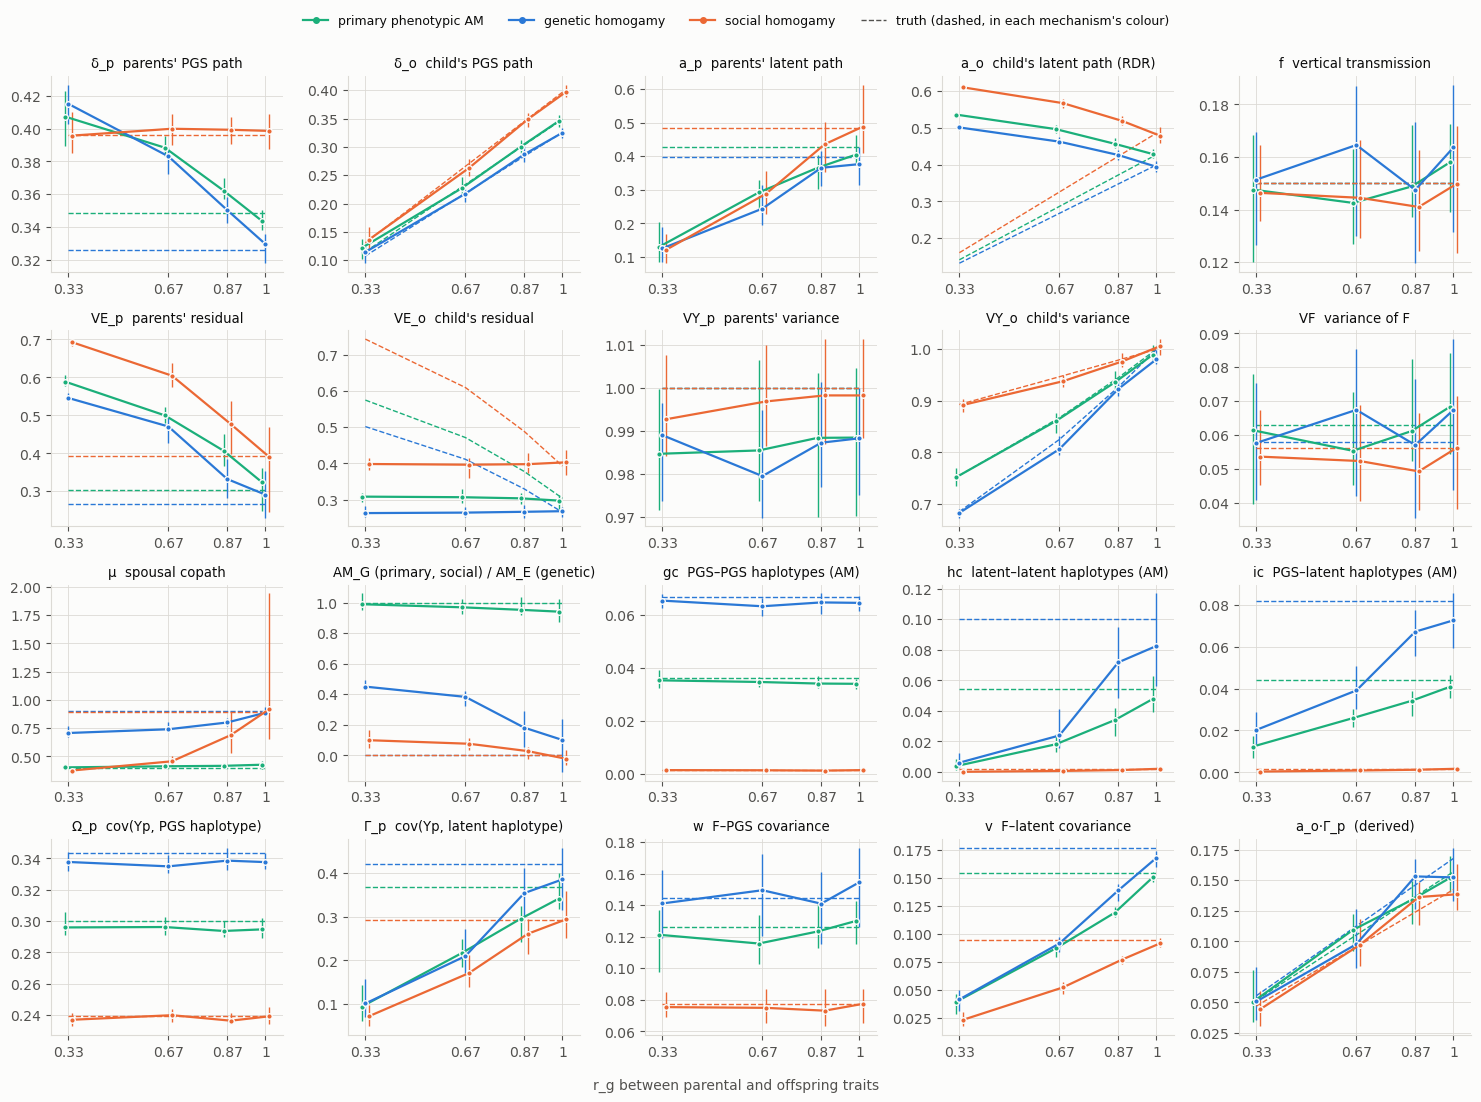

In [12]:
PANELS = [("delta_p11", "δ_p  parents' PGS path"), ("delta_o11", "δ_o  child's PGS path"),
          ("a_p11", "a_p  parents' latent path"), ("a_o11", "a_o  child's latent path (RDR)"), ("f11", "f  vertical transmission"),
          ("VE_parent", "VE_p  parents' residual"), ("VE_offspring", "VE_o  child's residual"),
          ("VY_parent", "VY_p  parents' variance"), ("VY_offspring", "VY_o  child's variance"), ("VF11", "VF  variance of F"),
          ("mu11", "µ  spousal copath"), ("AM", "AM_G (primary, social) / AM_E (genetic)"),
          ("gc11", "gc  PGS–PGS haplotypes (AM)"), ("hc11", "hc  latent–latent haplotypes (AM)"),
          ("ic11", "ic  PGS–latent haplotypes (AM)"),
          ("Omega_p11", "Ω_p  cov(Yp, PGS haplotype)"), ("Gamma_p11", "Γ_p  cov(Yp, latent haplotype)"),
          ("w11", "w  F–PGS covariance"), ("v11", "v  F–latent covariance"), ("aoGp", "a_o·Γ_p  (derived)")]
x = rdr[~rdr.pooled & (rdr.model == "EstA")]
est = x.pivot_table(index=["mechanism", "rg", "rep"], columns="parameter", values="estimate")
tru = x.pivot_table(index=["mechanism", "rg"], columns="parameter", values="true", aggfunc="first")
for d in (est, tru):
    d["AM"] = d.AMGenMulti.fillna(d.AMEnvMulti)            # the free mating multiplier of each mechanism
    d["aoGp"] = d.a_o11 * d.Gamma_p11                       # the latent genetic term of cov(Yo, Yp)
q = est.groupby(level=["mechanism", "rg"]).quantile([.25, .5, .75]).unstack()

fig, axes = plt.subplots(4, 5, figsize=(15, 11))
for ax, (p, title) in zip(axes.flat, PANELS):
    for k, mech in enumerate(MECHS):
        qq, tt = q.loc[mech], tru.loc[mech]
        ax.plot(tt.index, tt[p], ls="--", lw=1, color=COLOR[mech])
        ax.errorbar(qq.index + (k - 1) * .012, qq[(p, .5)], yerr=[qq[(p, .5)] - qq[(p, .25)], qq[(p, .75)] - qq[(p, .5)]],
                    color=COLOR[mech], lw=1.6, marker="o", ms=4, mec="#fcfcfb", mew=1, elinewidth=1, capsize=0)
    ax.set_title(title, fontsize=9.5, color=INK)
    ax.set_xticks(RG); ax.set_xticklabels([f"{r:g}" for r in RG]); ax.set_xlim(min(RG) - .06, 1.06)
handles = [plt.Line2D([], [], color=COLOR[m], lw=1.6, marker="o", ms=4, label=MLAB[m]) for m in MECHS]
handles.append(plt.Line2D([], [], color=INK2, lw=1, ls="--", label="truth (dashed, in each mechanism's colour)"))
fig.legend(handles=handles, loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(.5, 1.0))
fig.supxlabel("r_g between parental and offspring traits", fontsize=10, color=INK2)
fig.tight_layout(rect=(0, 0, 1, .965)); fig.savefig(PLOTS / "rdr_childA_parameters.png"); plt.show()

**Same trait with latent parents makes the bias worse.**
- **Without G×Age it works.** It is unbiased at r_g = 1 (+1%, 0%, +7%; z = 1.0, 0.1, 1.4) and, under primary AM and genetic homogamy, the most precise (MC SE .0017 and .0030).
- **Primary AM and genetic homogamy.** At every r_g < 1, its bias is larger than Model 2's:
  - r_g = .87: −30% and −39% (Model 2: −1% and −21%);
  - r_g = .67: −96% and −140%;
  - r_g = .33: −371% and −488%, with VÊ at its bound in 18 and 16 of 50 fits.
- **Social homogamy.** Here Model 2 has no bias, but this model is weakly identified even at r_g = 1: |µ̂| > 3 in 12 of 50 fits. G×Age makes f̂ unstable:
  - |µ̂| > 3 in 33, 16 and 17 fits at r_g = .33, .67 and .87;
  - VÊ at its bound in 20, 19 and 2 fits;
  - the mean f̂ is +731%, +74% and +38% off;
  - the medians are −16%, +23% and +24% off.

**Why it fails** (tables below). The model has one δ and one a for both generations, and the parents are latent, so nothing about them is measured.
- δ̂ follows the child: .125 at r_g = .33 under primary AM, against .349.
- The child's RDR pushes â up: .618, against .427.
- The parents' implied phenotypes are built from these child values. No free parameter can shrink the parent–child covariance, so f absorbs it. Under primary AM and genetic homogamy, f̂ is near zero or negative at r_g = .67 and strongly negative at .33.

In [13]:
print(MODEL_LAB["SameLat"], "- median estimates"); display(parTable("SameLat", P_LAT))

# degenerate same-trait latent fits: VE at its bound (.001) or an extreme copath
w = rdr[~rdr.pooled & (rdr.model == "SameLat")].pivot_table(index=["mechanism", "rg", "rep"], columns="parameter",
                                                            values="estimate")
deg = pd.DataFrame({"VE < .02": (w.VE11 < .02), "|µ| > 3": (w.mu11.abs() > 3)}).groupby(["mechanism", "rg"]).sum()
print("same trait, latent parents: fits out of 50 with VE at its bound or |µ| > 3")
deg.unstack("rg").reindex(MECHS)

same trait, latent parents - median estimates


true at r_g = 1  r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism par                                                              
primary   δ              0.349       0.125       0.226       0.301    0.344
          a              0.427       0.618       0.522       0.476    0.443
          VE             0.304       0.077       0.234       0.253    0.269
          µ              0.400       1.716       0.731       0.481    0.381
          VF             0.063       0.750       0.001       0.029    0.062
genetic   δ              0.326       0.157       0.214       0.289    0.327
          a              0.399       0.579       0.478       0.434    0.395
          VE             0.265       0.029       0.225       0.245    0.262
          µ              0.905       0.471       0.875       0.904    0.894
          VF             0.058       0.705       0.008       0.024    0.059
social    δ              0.396       0.141       0.266       0.351    0.398
          a              0.485       0.508       0.653       0.536    0.482
          VE             0.393       0.970       0.111       0.348    0.396
          µ              0.891      -0.008       0.966       0.247    0.206
          VF             0.056      -0.030       0.059       0.051    0.053

same trait, latent parents: fits out of 50 with VE at its bound or |µ| > 3


VE < .02                |µ| > 3               
rg            0.33 0.67 0.87 1.00    0.33 0.67 0.87 1.00
mechanism                                               
primary         18    0    2    0       0    0    0    0
genetic         16    0    0    0       0    0    0    0
social          20   19    2    2      33   16   17   12

### 4.2 The corrections that also need the parents' RDR: RDR on both a, and different traits with latent parents

- **RDR on both a** (`UniSEMPGS_Cascade_DiffTrait_ObservedYPYM_FixedAParent.R`): as RDR on the child's a, but the parents' RDR also fixes a_p.
- **Different traits, latent parents** (`UniSEMPGS_Cascade_DiffTrait_LatentYPYM.R`):
  - only the child's phenotype and the four PGS haplotypes;
  - its own δ and a for parents and child, with both a fixed by RDR;
  - the copath µ fixed at its true value (the script needs it);
  - one VY shared by both generations;
  - both mating multipliers fixed at the true mechanism.

Both need RDR in the parents' generation. The latent model also needs the true µ, which real data do not give.

The tables and the figure are laid out as in 4.1. A further table counts the latent model's fits with a_p at its lower bound.

relative bias of f (%): mean of the 50 population estimates minus .15, divided by .15


r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                        
primary   Model 2 (no RDR)                       -55.4       -20.9        -1.0      5.4
          RDR on both a                          -23.7        -8.4        -1.8      0.8
          different traits, latent parents       -18.3        -8.8        -3.4     -2.9
genetic   Model 2 (no RDR)                      -218.4       -55.1       -21.1      6.7
          RDR on both a                            2.8         9.7        11.4     -3.7
          different traits, latent parents        -6.8         6.7         6.5     -5.6
social    Model 2 (no RDR)                         4.6         2.2        -2.7     -0.6
          RDR on both a                          -51.4       -26.3        -9.7     -0.3
          different traits, latent parents         4.9         8.8        13.1     10.9

relative bias of f (%), median of the 50 population estimates


r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                        
primary   Model 2 (no RDR)                       -55.9       -21.3        -5.7      4.9
          RDR on both a                          -23.3        -8.6        -1.3      0.3
          different traits, latent parents       -17.6        -8.2        -3.0     -1.7
genetic   Model 2 (no RDR)                      -222.3       -49.7       -22.7     11.6
          RDR on both a                            2.3         9.9        11.9      2.9
          different traits, latent parents        -6.6         7.1        13.3     -3.4
social    Model 2 (no RDR)                         3.9         0.6        -3.8      1.3
          RDR on both a                          -50.3       -26.2        -9.7     -0.5
          different traits, latent parents        22.4        30.3        36.0     38.7

MC SE of a mean f̂


r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                        
primary   Model 2 (no RDR)                      0.0136      0.0056      0.0045   0.0041
          RDR on both a                         0.0007      0.0009      0.0009   0.0012
          different traits, latent parents      0.0012      0.0007      0.0004   0.0008
genetic   Model 2 (no RDR)                      0.0147      0.0134      0.0068   0.0060
          RDR on both a                         0.0008      0.0010      0.0010   0.0042
          different traits, latent parents      0.0005      0.0007      0.0059   0.0060
social    Model 2 (no RDR)                      0.0045      0.0046      0.0041   0.0045
          RDR on both a                         0.0015      0.0010      0.0008   0.0009
          different traits, latent parents      0.0057      0.0063      0.0070   0.0073

different traits, latent parents: fits out of 50 with a_p at its bound, and their mean f̂ vs the others'


a_p at bound  mean f̂, a_p at bound  mean f̂, other fits
mechanism rg                                                            
primary   0.33             0                    NaN                0.123
          0.67             0                    NaN                0.137
          0.87             0                    NaN                0.145
          1.00             0                    NaN                0.146
genetic   0.33             0                    NaN                0.140
          0.67             0                    NaN                0.160
          0.87             0                    NaN                0.160
          1.00             0                    NaN                0.142
social    0.33            19                  0.108                0.188
          0.67            19                  0.108                0.197
          0.87            18                  0.106                0.205
          1.00            21                  0.108                0.209

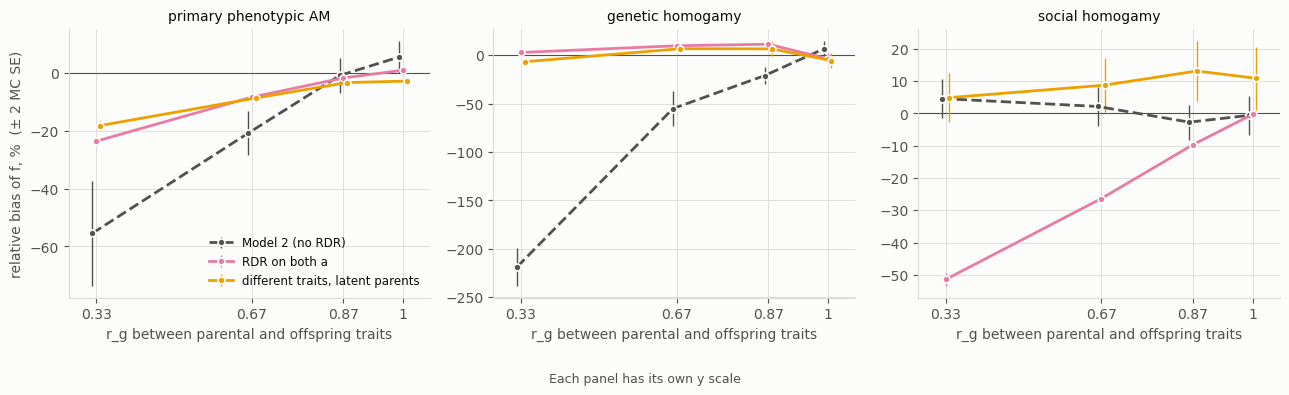

In [14]:
print("relative bias of f (%): mean of the 50 population estimates minus .15, divided by .15")
display(byRG("relative bias (%)", OTHER))
print("relative bias of f (%), median of the 50 population estimates")
display(byRG("median f̂", OTHER, 4).sub(F_TRUE).div(F_TRUE).mul(100).round(1))
print("MC SE of a mean f̂")
display(byRG("MC SE", OTHER, 4))
w = rdr[~rdr.pooled & (rdr.model == "DiffLat")].pivot_table(index=["mechanism", "rg", "rep"], columns="parameter",
                                                            values="estimate")
lowA = w.a_p11 < .01
print("different traits, latent parents: fits out of 50 with a_p at its bound, and their mean f̂ vs the others'")
display(pd.DataFrame({"a_p at bound": lowA.groupby(["mechanism", "rg"]).sum(),
                      "mean f̂, a_p at bound": w.f11[lowA].groupby(["mechanism", "rg"]).mean(),
                      "mean f̂, other fits": w.f11[~lowA].groupby(["mechanism", "rg"]).mean()})
        .reindex(MECHS, level=0).round(3))
modelLines(OTHER, "rdr_other_bias_f.png")

**RDR on both a only partly corrects the bias, and adds one under social homogamy.**
- **Without G×Age.** It is unbiased at r_g = 1: +1%, −4%, 0%.
  - The genetic-homogamy mean is pulled down by 7 fits with f̂ between .060 and .105; the median is +3%.
- **Primary AM.** It halves Model 2's bias or better: −8% at r_g = .67 and −24% at .33, against −21% and −55%. At .87 both are near zero (−2% and −1%).
- **Genetic homogamy.** It removes most of Model 2's bias but overshoots: +11%, +10% and +3% at r_g = .87, .67 and .33. Model 2 has −21%, −55% and −218%.
- **Social homogamy.** Here Model 2 is unbiased, but this model is biased: −10%, −26% and −51% at r_g = .87, .67 and .33.
- **Precision.** Its estimates are very precise (MC SE ≤ .0015, except .0042 under genetic homogamy at r_g = 1). So even its 10% biases are many MC SEs: z reaches −53.
- **Why** (median â_p in the table at the end):
  - The parents' RDR ties â_p to the parents' heritability. Under social homogamy and primary AM, it keeps â_p from falling as far as with RDR on the child's a (r_g = .33: .382 against .121 under social homogamy, .215 against .130 under primary AM). The parent–child covariance that â_p can no longer absorb goes to f.
  - Under genetic homogamy, â_p falls about as far as with RDR on the child's a, and the bias is smaller.

**Different traits with latent parents** has a small bias under primary AM and genetic homogamy, and is bimodal under social homogamy at every r_g.
- **Primary AM.** −3%, −9% and −18% at r_g = .87, .67 and .33, and −3% at r_g = 1. Its MC SE is ≤ .0012, so even the −3% at r_g = 1 is z = −5.3: a small bias without G×Age.
- **Genetic homogamy.** Within ±7% at every r_g: +7%, +7% and −7% at r_g = .87, .67 and .33, and −6% at r_g = 1. f̂ is at its lower bound (.001) in 3 fits at r_g = .87 and in 2 at r_g = 1.
- **Social homogamy.** The fits fall into two groups at every r_g, including r_g = 1:
  - 18–21 of 50 fits have â_p at its lower bound and f̂ ≈ .106–.108 (about −28%);
  - the others have f̂ = .188–.209 (+25% to +39%).
  - The mean (+5% to +13%) averages two wrong answers. This is a property of the model under social homogamy, not of G×Age.

In [15]:
x = rdr[~rdr.pooled & (rdr.parameter == "a_p11") & rdr.model.isin(["EstA", "FixA", "DiffLat"])]
t = x.pivot_table(index=["mechanism", "model"], columns="rg", values="estimate", aggfunc="median")
t.columns = [f"r_g = {r:g}" for r in t.columns]
t.insert(0, "true at r_g = 1", x[x.rg == 1].groupby(["mechanism", "model"]).true.first())
print("median estimate of a_p, the parents' latent genetic path")
t.reindex(MECHS, level=0).reindex(["EstA", "FixA", "DiffLat"], level=1).rename(index=MODEL_LAB, level=1).round(3)

median estimate of a_p, the parents' latent genetic path


true at r_g = 1  r_g = 0.33  r_g = 0.67  r_g = 0.87  r_g = 1
mechanism model                                                                                         
primary   RDR on the child's a                        0.427       0.130       0.292       0.366    0.405
          RDR on both a                               0.427       0.215       0.306       0.373    0.430
          different traits, latent parents            0.427       0.279       0.342       0.402    0.449
genetic   RDR on the child's a                        0.399       0.126       0.244       0.366    0.377
          RDR on both a                               0.399       0.119       0.234       0.319    0.392
          different traits, latent parents            0.399       0.216       0.283       0.334    0.412
social    RDR on the child's a                        0.485       0.121       0.288       0.436    0.488
          RDR on both a                               0.485       0.382       0.424       0.463    0.486
          different traits, latent parents            0.485       0.628       0.641       0.674    0.682

## 5. Summary

- **Model 2.** G×Age biases f downward under primary AM and genetic homogamy, and more steeply as r_g falls.
  - Under primary AM, r_g = .87 is harmless (−1%), but −21% at .67 and −55% at .33.
  - Genetic homogamy is the most sensitive: −21% at .87, −55% at .67, and the wrong sign at .33.
  - Under social homogamy, Model 2 is unbiased at every r_g.
- **RDR on the child's a is the correction to use.**
  - It removes the bias at every r_g and under every mechanism (within ±7%, |z| < 1.7), at no cost in precision.
  - It needs only the child's RDR heritability, from the generation whose phenotype is measured.
  - Under G×Age, its â_p and VÊ_p absorb the mismatch and are not the parents' values.
- **Same trait with latent parents is not a correction.** It is unbiased without G×Age. With G×Age it is more biased than Model 2 under primary AM and genetic homogamy, and unstable under social homogamy.
- **RDR on both a** reduces Model 2's bias under primary AM and genetic homogamy, but adds a bias of −10% to −51% under social homogamy.
- **Different traits with latent parents** is within ±9% at r_g ≥ .67 under primary AM and genetic homogamy (−18% at .33 under primary AM). Under social homogamy it is bimodal at every r_g, and it needs the true µ.

### Scope

- **RDR inputs.** They are the true population values, with no RDR sampling error. How an estimated RDR heritability affects RDR on the child's a is not tested here.
- **The child's RDR.** It is what RDR run on children would estimate: all of the child's genetic variance, including the child-only part.
- **One setting.** f = .15, am = .4, VY = 1 in the parents. 50 populations of 10,000 per generation, about 4,050 trios each, per mechanism × r_g.
- **G×Age in the genetic value only.** The child's residual variance equals the adult's (VE_o = VE), and the PGS carries the adult effects (an adult GWAS).
- **No feedback.** Spouses assort on, and parents transmit through, their adult phenotypes. A design where a phenotype expressed at another age feeds back into mating or transmission could behave differently.
- **Baseline.** At r_g = 1, Model 2 and RDR on the child's a sit 3–7% above .15 under primary AM and genetic homogamy (z ≤ 2.0). Model 2's G×Age biases under these two mechanisms are much larger than this baseline, except at r_g = .87 under primary AM.